# Resultados y discusión: presencia en el videoclip interactivo VR

**Fuente de datos:** `Resultados-IPQ.xlsx`, exportación de KoboToolbox ubicada junto a este cuaderno. Se analizan únicamente respuestas con autorización para investigación. Las dos respuestas sin código de participante son válidas según la confirmación del equipo investigador.

**Instrumento de referencia:** Castro et al. (2026), [adaptación española del ITQ e IPQ](https://doi.org/10.1007/s10055-025-01301-2), Apéndice 2. El formulario aplicado (`../../IPQ_KoboToolbox3.xlsx`) conserva los 14 enunciados y el rango de −3 a +3, pero presenta los mismos anclajes de acuerdo/desacuerdo en los 14 ítems. El artículo usa anclajes específicos según la pregunta. Por ello, las puntuaciones de este cuaderno son **descriptivas de la administración efectuada** y no equivalen a las tres subescalas validadas del artículo.

El análisis evita mostrar códigos, identificadores y comentarios individuales.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

archivo = Path("Resultados-IPQ.xlsx")
if not archivo.exists():
    raise FileNotFoundError(f"No se encontró {archivo.resolve()}")

exportacion = pd.read_excel(archivo)
assert exportacion.shape[1] >= 34, "Cambió la estructura de columnas de la exportación"
assert "research_use_flag" in exportacion, "Falta la columna de consentimiento"

# La exportación contiene caracteres dañados en algunos encabezados; se usan
# las posiciones verificadas del XLSForm y se comprueba el número de ítem.
columnas_ipq = {f"q{i}": exportacion.columns[12 + i] for i in range(1, 15)}
for i, encabezado in enumerate(columnas_ipq.values(), start=1):
    assert str(encabezado).startswith(f"{i}."), f"Cambió el orden del ítem {i}"

consentidas = exportacion.loc[
    pd.to_numeric(exportacion["research_use_flag"], errors="coerce").eq(1)
].copy()
respuestas = pd.DataFrame({
    nombre: pd.to_numeric(consentidas[columna], errors="coerce")
    for nombre, columna in columnas_ipq.items()
}, index=consentidas.index)

# No se imputan respuestas faltantes ni se excluyen registros por falta de código.
valores_fuera_de_rango = ((respuestas < -3) | (respuestas > 3)).sum().sum()
assert valores_fuera_de_rango == 0, "Se encontraron respuestas IPQ fuera de -3 a +3"


## 1. Revisión de la base

La **Tabla 1** resume el número de registros y la completitud del IPQ. Para cada indicador posterior se usan solamente las respuestas disponibles para sus ítems; por eso cambia el denominador. *Fuente: elaboración propia a partir de la exportación de KoboToolbox.*

In [2]:
faltantes_por_fila = respuestas.isna().sum(axis=1)
revision = pd.DataFrame({
    "Medida": [
        "Registros exportados", "Registros con consentimiento",
        "IPQ completo (14 ítems)", "IPQ con 1 respuesta faltante",
        "IPQ con 2 respuestas faltantes"#, "Registros consentidos sin código"
    ],
    "Cantidad": [
        len(exportacion), len(consentidas), int((faltantes_por_fila == 0).sum()),
        int((faltantes_por_fila == 1).sum()),
        int((faltantes_por_fila == 2).sum())#,
        #int(consentidas.iloc[:, 10].isna().sum())
    ]
})
display(revision)


,Medida,Cantidad
0,Registros exportados,35
1,Registros con consentimiento,35
2,IPQ completo (14 ítems),31
3,IPQ con 1 respuesta faltante,1
4,IPQ con 2 respuestas faltantes,3


## 2. Indicadores de presencia

La adaptación española distingue presencia espacial (5 ítems), involucramiento (4), realismo (4) y un ítem de presencia general. Sus anclajes varían según el enunciado. En el formulario Kobo, los ítems **1, 2, 4 y 5** son preguntas de grado presentadas con extremos de acuerdo/desacuerdo; sus valores no se incorporan a las subescalas. En esta aplicación el ítem **6** sí requiere invertir el signo, porque su enunciado es negativo y se respondió mediante acuerdo/desacuerdo. También se invierten los ítems **11 y 13**. [Véase el Apéndice 2 del artículo](https://doi.org/10.1007/s10055-025-01301-2).

La **Tabla 2** presenta un indicador exploratorio de presencia espacial, el ítem de presencia general y los ítems interpretables de involucramiento y realismo. Se exige respuesta en todos los ítems de cada promedio. Estos indicadores **no deben compararse con puntuaciones de las subescalas validadas**. *Fuente: elaboración propia a partir de `Resultados-IPQ.xlsx`.*

In [3]:
indicadores = pd.DataFrame(index=respuestas.index)
indicadores["Presencia general (ítem 8)"] = respuestas["q8"]
espaciales = pd.DataFrame({
    "q3": respuestas["q3"], "q6_invertido": -respuestas["q6"],
    "q9": respuestas["q9"], "q10": respuestas["q10"],
    "q13_invertido": -respuestas["q13"]
})
indicadores["Presencia espacial (5 ítems, exploratoria)"] = (
    espaciales.mean(axis=1).where(espaciales.notna().all(axis=1))
)
indicadores["No fui consciente del ambiente real (ítem 7)"] = respuestas["q7"]
indicadores["Atención al ambiente real, invertida (ítem 11)"] = -respuestas["q11"]
indicadores["Cautivado por el mundo virtual (ítem 14)"] = respuestas["q14"]
indicadores["Más realista que el mundo real (ítem 12)"] = respuestas["q12"]

resumen_presencia = pd.DataFrame({
    "Indicador": indicadores.columns,
    "n": indicadores.count().to_numpy(),
    "Media": indicadores.mean().to_numpy(),
    "DE": indicadores.std(ddof=1).to_numpy(),
    "Mediana": indicadores.median().to_numpy()
})
display(resumen_presencia.round(2))


,Indicador,n,Media,DE,Mediana
0,Presencia general (ítem 8),34,2.03,1.19,2.0
1,"Presencia espacial (5 ítems, exploratoria)",32,1.87,0.95,1.9
2,No fui consciente del ambiente real (ítem 7),35,0.63,1.70,1.0
3,"Atención al ambiente real, invertida (ítem 11)",34,0.12,1.70,0.0
4,Cautivado por el mundo virtual (ítem 14),35,1.80,1.13,2.0
5,Más realista que el mundo real (ítem 12),35,-0.46,2.12,0.0


La **Figura 1** presenta la distribución de respuestas al ítem de presencia general. *Fuente: elaboración propia a partir de `Resultados-IPQ.xlsx`.*

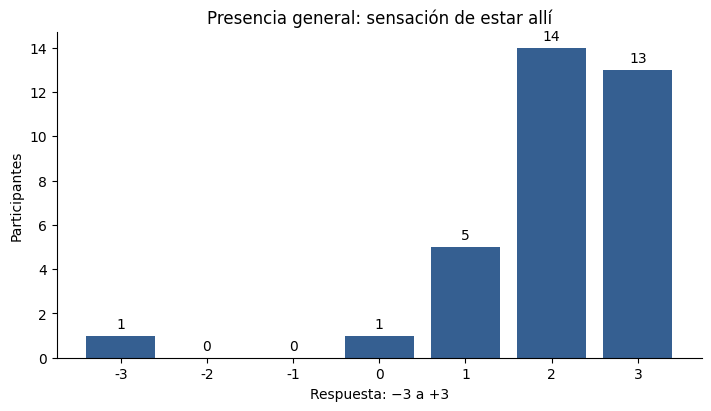

In [4]:
general_frecuencias = (
    respuestas["q8"].value_counts().reindex(range(-3, 4), fill_value=0).sort_index()
)
fig, eje = plt.subplots(figsize=(7, 4), constrained_layout=True)
barras = eje.bar(general_frecuencias.index.astype(str), general_frecuencias.values, color="#355f91")
eje.set(title="Presencia general: sensación de estar allí",
        xlabel="Respuesta: −3 a +3", ylabel="Participantes")
eje.set_ylim(bottom=0)
eje.spines[["top", "right"]].set_visible(False)
eje.bar_label(barras, padding=3)
plt.show()


## 3. Resultados redactados para el capítulo

El siguiente bloque genera un texto con las cifras de esta exportación. Cita la Tabla 1, la Tabla 2 y la Figura 1 al trasladarlas a la tesis.

In [5]:
def es(numero, decimales=2):
    return f"{numero:.{decimales}f}".replace(".", ",")

n_general = int(respuestas["q8"].count())
positivos_general = int(respuestas["q8"].gt(0).sum())
media_general = indicadores["Presencia general (ítem 8)"].mean()
media_espacial = indicadores["Presencia espacial (5 ítems, exploratoria)"].mean()
realismo_item = respuestas["q12"].dropna()

texto_resultados = f"""
### Texto propuesto: Resultados

La base contenía **{len(exportacion)} registros**, todos con autorización para el uso de sus respuestas en la investigación. De ellos, **{int((faltantes_por_fila == 0).sum())}** respondieron los 14 ítems y **{int((faltantes_por_fila > 0).sum())}** presentaron una o dos respuestas faltantes (Tabla 1). Se conservaron las dos respuestas válidas sin código de participante.

La sensación general de «estar allí» obtuvo una media de **{es(media_general)}** (DE = {es(respuestas['q8'].std(ddof=1))}; n = {n_general}). **{positivos_general} de {n_general}** respuestas fueron positivas. El indicador exploratorio de presencia espacial promedió **{es(media_espacial)}** (DE = {es(indicadores['Presencia espacial (5 ítems, exploratoria)'].std(ddof=1))}; n = {int(indicadores['Presencia espacial (5 ítems, exploratoria)'].count())}) (Tabla 2). La Figura 1 muestra la distribución del ítem de presencia general.

En el ítem «El mundo virtual me pareció más realista que el mundo real» se registraron **{int(realismo_item.lt(0).sum())}** respuestas negativas, **{int(realismo_item.eq(0).sum())}** neutras y **{int(realismo_item.gt(0).sum())}** positivas. Este ítem aislado no constituye una puntuación de la dimensión completa de realismo (Tabla 2).
"""
display(Markdown(texto_resultados))



### Texto propuesto: Resultados

La base contenía **35 registros**, todos con autorización para el uso de sus respuestas en la investigación. De ellos, **31** respondieron los 14 ítems y **4** presentaron una o dos respuestas faltantes (Tabla 1). Se conservaron las dos respuestas válidas sin código de participante.

La sensación general de «estar allí» obtuvo una media de **2,03** (DE = 1,19; n = 34). **32 de 34** respuestas fueron positivas. El indicador exploratorio de presencia espacial promedió **1,87** (DE = 0,95; n = 32) (Tabla 2). La Figura 1 muestra la distribución del ítem de presencia general.

En el ítem «El mundo virtual me pareció más realista que el mundo real» se registraron **17** respuestas negativas, **5** neutras y **13** positivas. Este ítem aislado no constituye una puntuación de la dimensión completa de realismo (Tabla 2).


## 4. Discusión e interpretación

**Objetivos de implementación.** El código del proyecto define canales de eventos, una secuencia configurable y un reloj musical compartido. Este cuaderno analiza respuestas de usuarios; no contiene registros instrumentados de latencia, tiempo de carga o desfase audiovisual. Por ello, los resultados de presencia no deben presentarse como prueba cuantitativa de precisión técnica ni como un efecto causado por la arquitectura.

**Presencia percibida.** Las respuestas del ítem general y el indicador espacial exploratorio fueron predominantemente positivas en esta muestra. En cambio, la afirmación de que el mundo virtual parecía *más realista que el real* dividió las opiniones. Esa frase establece una comparación exigente y no resume, por sí sola, toda la dimensión de realismo.

**Alcance del IPQ aplicado.** El [artículo de Castro et al.](https://doi.org/10.1007/s10055-025-01301-2) publica anclajes diferentes según el ítem y advierte dificultades de fiabilidad para realismo. El formulario Kobo unificó los anclajes y, con ello, modificó la administración del instrumento. Además, el artículo excluyó del modelo factorial revisado «Me sentí completamente cautivado por el mundo virtual» debido a cargas en varios factores. Se conservan aquí las respuestas observadas, pero no se calculan puntuaciones completas de involucramiento y realismo ni se comparan estos resultados con normas o medias de la versión validada.

**Límites del diseño.** Se usó una muestra de conveniencia sin grupo de comparación. Treinta y cuatro participantes indicaron que no era su primera vez en VR y uno no respondió esa pregunta. Los resultados describen a quienes respondieron la encuesta; no permiten generalizar estadísticamente a todos los usuarios ni aceptar o rechazar una hipótesis causal que no haya sido formulada y contrastada.

**Siguiente aplicación.** Para usar las tres subescalas como en el artículo, el formulario deberá reproducir los anclajes de cada pregunta antes de recolectar una nueva muestra. Los datos actuales deben conservarse como evidencia de esta aplicación, documentando el formato realmente presentado a los participantes.